# Tarea Clase 6 – 2.1 Procesos estocásticos estacionarios y no estacionarios
## Ruido blanco y caminata aleatoria: simulación y aplicación a acciones

**Econometría Financiera – FZ4038** · EGADE Business School, Tecnológico de Monterrey  
**Profesor:** Dr. Raymundo Díaz Robles  
**Alumno:** Daniel Mondragón Monroy (A01452205)  
**Fecha:** 9 de noviembre de 2026  
**Repositorio GitHub:** [https://github.com/a01452205/FZ4038-Tarea6-2.1](https://github.com/a01452205/FZ4038-Tarea6-2.1)

---

<a id="contenido"></a>
**Contenido**

1. [Introducción y objetivo](#sec-1)
2. [Marco conceptual y notación](#sec-2)
    - [2.1 Proceso estocástico](#sec-2-1)
    - [2.2 Ruido blanco](#sec-2-2)
    - [2.3 Caminata aleatoria (random walk)](#sec-2-3)
    - [2.4 Notación de las variables](#sec-2-4)
3. [Parte 1: Ruido blanco y caminata aleatoria simulados](#sec-3)
    - [3.1 Ejercicio en Excel](#sec-3-1)
    - [3.2 Réplica en Python: una realización](#sec-3-2)
    - [3.3 Muchas realizaciones (el equivalente a presionar F9)](#sec-3-3)
    - [3.4 Verificación numérica de las propiedades (simulación de Monte Carlo)](#sec-3-4)
4. [Parte 2: Ruido blanco y caminata aleatoria en las acciones seleccionadas](#sec-4)
    - [4.1 Datos](#sec-4-1)
    - [4.2 Hipótesis](#sec-4-2)
    - [4.3 Raíz unitaria: ¿el log-precio es caminata aleatoria?](#sec-4-3)
    - [4.4 Ruido blanco: ¿los rendimientos están autocorrelacionados? ¿son independientes?](#sec-4-4)
    - [4.5 Razón de varianzas: ¿la varianza crece proporcional al horizonte?](#sec-4-5)
    - [4.6 ¿Se distingue una acción de una caminata aleatoria simulada?](#sec-4-6)
    - [4.7 Resumen por activo](#sec-4-7)
5. [Conclusiones](#sec-5)
6. [Referencias](#sec-6)

<a id="sec-1"></a>
## 1. Introducción y objetivo

<small>[↑ Volver al contenido](#contenido)</small>

El objetivo de esta actividad es **reconocer procesos estocásticos estacionarios y no estacionarios** a partir de los dos procesos más básicos en series de tiempo: el **ruido blanco** (estacionario) y la **caminata aleatoria** (no estacionaria).

La actividad tiene dos partes:

- **Parte 1 (sección 3).** Se resuelve en Excel el ejercicio de la guía: se construye un ruido blanco con números aleatorios uniformes y se acumula para formar una caminata aleatoria (archivo `Tarea_Clase_6-2.1_A01452205_EjercicioClase.xlsx`). Después se replica en Python y se simulan miles de realizaciones para **verificar numéricamente** las propiedades teóricas de la caminata aleatoria, algo que Excel no permite hacer con facilidad.
- **Parte 2 (sección 4).** Se responde la pregunta con la que termina la guía: *¿se puede tomar una serie y saber si es o no caminata aleatoria?* Para ello se analizan los precios y rendimientos diarios de las acciones del portafolio, con pruebas formales de raíz unitaria, de ruido blanco y de razón de varianzas.

Esta actividad es también la base de la etapa de **identificación** de la metodología Box-Jenkins (Gujarati y Porter, 2009, caps. 21 y 22) que se usará en el proyecto final para los modelos ARIMA y GARCH.

<a id="sec-2"></a>
## 2. Marco conceptual y notación

<small>[↑ Volver al contenido](#contenido)</small>

<a id="sec-2-1"></a>
### 2.1 Proceso estocástico

Un **proceso estocástico** es una sucesión de variables aleatorias ordenadas en el tiempo, $\{X_t\}_{t=1}^{T}$. Una serie de tiempo observada (por ejemplo, el precio diario de una acción) es **una sola realización** de ese proceso.

<a id="sec-2-2"></a>
### 2.2 Ruido blanco

Un proceso $\{\varepsilon_t\}$ es **ruido blanco** si:

1. Sus elementos son independientes e idénticamente distribuidos (*i.i.d.*);
2. $E[\varepsilon_t] = 0$;
3. $\operatorname{Var}(\varepsilon_t) = \sigma^2$ (constante);
4. $\operatorname{Cov}(\varepsilon_t, \varepsilon_s) = 0$ para $t \neq s$.

Es un proceso **estacionario**: su media, su varianza y sus covarianzas no cambian con el tiempo.

<a id="sec-2-3"></a>
### 2.3 Caminata aleatoria (*random walk*)

La caminata aleatoria parte de cero y acumula elementos de un ruido blanco:

$$S_0 = 0, \qquad S_t = S_{t-1} + \varepsilon_t = \sum_{i=1}^{t} \varepsilon_i$$

Sus propiedades (Ilustración 3 de la guía) son:

| Propiedad | Expresión | Significado |
|:--|:--|:--|
| Valor esperado no condicional | $E[S_t] = 0$ | En promedio, la caminata no se aleja del origen |
| Valor esperado condicional | $E[S_t \mid S_{t-1}] = S_{t-1}$ | El mejor pronóstico de mañana es el valor de hoy |
| Varianza | $\operatorname{Var}(S_t) = t\,\sigma^2$ | La incertidumbre **crece con el tiempo** |
| Covarianza | $\operatorname{Cov}(S_t, S_s) = \min(t,s)\,\sigma^2$ | Dos puntos de la caminata comparten los choques comunes |

Como su varianza depende de $t$, la caminata aleatoria es **no estacionaria**. Su primera diferencia, $\Delta S_t = \varepsilon_t$, es ruido blanco: por eso se dice que es un proceso **integrado de orden 1**, $I(1)$.

<a id="sec-2-4"></a>
### 2.4 Notación de las variables

| Símbolo | Variable | Definición |
|:--|:--|:--|
| $t$ | Tiempo | Periodo (0 a 100 en la simulación; día hábil en las acciones) |
| $U_t$ | Número aleatorio | $U_t \sim \text{Uniforme}[0,1)$, equivalente a `=ALEATORIO()` en Excel |
| $\varepsilon_t$ | Ruido blanco | $\varepsilon_t = (U_t - 0.5)/0.5 \sim \text{Uniforme}[-1,1)$; $E[\varepsilon_t]=0$, $\sigma^2 = 1/3$ |
| $S_t$ | Caminata aleatoria | $S_t = S_{t-1} + \varepsilon_t$, con $S_0 = 0$ |
| $P_{i,t}$ | Precio | Precio de cierre ajustado de la acción $i$ en el día $t$ (USD) |
| $p_{i,t}$ | Log-precio | $p_{i,t} = \ln P_{i,t}$ |
| $r_{i,t}$ | Rendimiento | Rendimiento logarítmico diario en %: $r_{i,t} = 100\,(p_{i,t} - p_{i,t-1})$ |

La varianza del ruido blanco uniforme en $[-1,1)$ es $\sigma^2 = \frac{(b-a)^2}{12} = \frac{2^2}{12} = \frac{1}{3}$.

In [1]:
# Paquetes
!pip -q install yfinance

import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from IPython.display import display

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
pd.set_option("display.width", 160)

<a id="sec-3"></a>
## 3. Parte 1: Ruido blanco y caminata aleatoria simulados

<small>[↑ Volver al contenido](#contenido)</small>

<a id="sec-3-1"></a>
### 3.1 Ejercicio en Excel

El ejercicio se resolvió en Excel siguiendo la Ilustración 4 de la guía (archivo `Tarea_Clase_6-2.1_A01452205_EjercicioClase.xlsx`, hoja *RandomWalk*):

| Columna | Variable | Fórmula en Excel | Qué hace |
|:--|:--|:--|:--|
| A | Tiempo $t$ | 0, 1, …, 100 | Eje del tiempo |
| B | Observaciones del fenómeno $U_t$ | `=RAND()` (`=ALEATORIO()`) | Número aleatorio uniforme en $[0,1)$, con media 0.5 |
| C | Ruido blanco $\varepsilon_t$ | `=(B-0.5)/0.5` | Resta la media (0.5) para obtener la **desviación o error**, con media cero; al dividir entre 0.5 lleva el rango a $[-1,1)$ |
| D | Caminata aleatoria $S_t$ | `=C7+C6` en $t=1$; después `=Cₜ+Dₜ₋₁` | Acumula los choques: $S_t = S_{t-1} + \varepsilon_t$ |

La captura muestra una realización (los valores cambian cada vez que Excel recalcula):

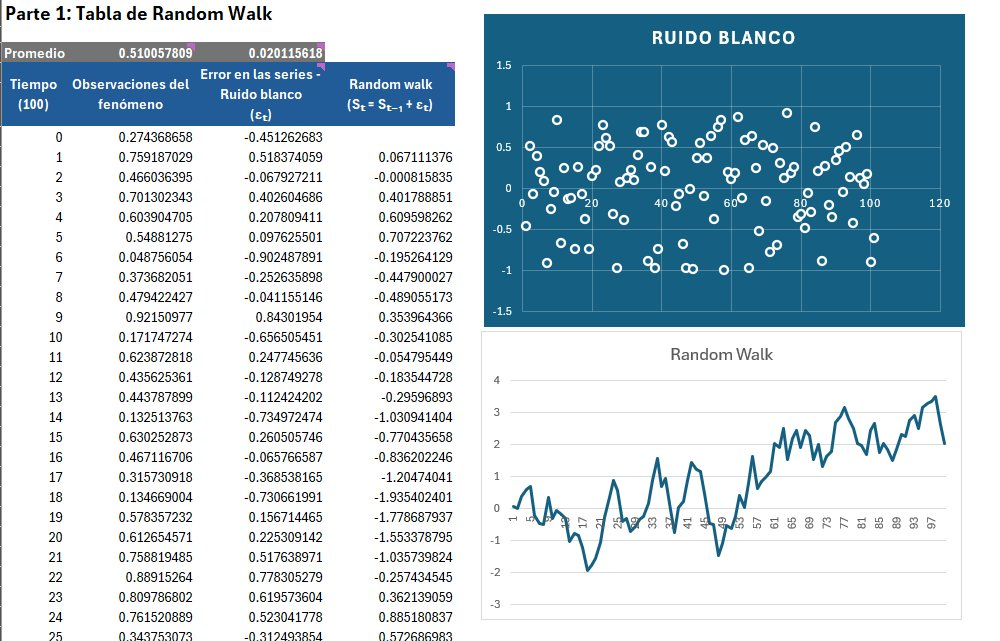

**Interpretación del ejercicio en Excel.**

- **Promedios.** El promedio de $U_t$ es 0.51, cercano a su media teórica de 0.5, y el del ruido blanco $\varepsilon_t$ es 0.02, cercano a cero. Esto confirma que restar 0.5 centra el ruido en cero.
- **Ruido blanco.** La gráfica es una nube de puntos sin patrón alrededor de cero, con la misma dispersión al inicio y al final: es un proceso **estacionario**. Ver un punto no ayuda a adivinar el siguiente.
- **Caminata aleatoria.** Aunque se construye solo con ese ruido, la gráfica muestra rachas que parecen tendencias: baja hasta cerca de −2 alrededor de $t = 18$ y luego sube hasta cerca de 3.5 hacia $t = 97$. No son tendencias reales, sino la **acumulación** de choques aleatorios: la caminata tiene memoria porque cada valor contiene todos los choques anteriores. Es un proceso **no estacionario**.
- **Al presionar F9** el ruido blanco siempre se ve igual (una nube), mientras que la caminata cambia por completo de forma: cada recálculo es una **realización** distinta del mismo proceso.
- **Nota sobre el promedio de la caminata.** No se calcula el promedio de la columna D porque el promedio de una sola trayectoria a lo largo del tiempo no estima $E[S_t]=0$. Ese valor esperado es el promedio de **muchas realizaciones** en un mismo $t$, y se verifica en la sección 3.4 con 10,000 simulaciones.
- **Diferencia con la guía.** La guía inicia la caminata en $S_0 = 0$; en el Excel la primera acumulación incluye el choque de $t=0$ ($S_1 = \varepsilon_0 + \varepsilon_1$). La diferencia no cambia el comportamiento del proceso.

<a id="sec-3-2"></a>
### 3.2 Réplica en Python: una realización

Se replica la Ilustración 4 de la guía: el tiempo va de 0 a 100; para $t \ge 1$ se genera $U_t$ con distribución uniforme (`=ALEATORIO()`), se transforma en ruido blanco con $\varepsilon_t = (U_t - 0.5)/0.5$ y se acumula para obtener $S_t$, con $S_0 = 0$.

Se fija una **semilla** para que los resultados sean reproducibles. Cambiar la semilla equivale a presionar **F9** en Excel.

,Tiempo t,Aleatorio U_t,Ruido blanco ε_t,Caminata aleatoria S_t
0,0,NaN,NaN,0.0000
1,1,0.1789,-0.6421,-0.6421
2,2,0.6399,0.2798,-0.3623
3,3,0.4673,-0.0655,-0.4278
4,4,0.3705,-0.2590,-0.6868
5,5,0.3549,-0.2902,-0.9769
6,6,0.7905,0.5810,-0.3959
7,7,0.9051,0.8103,0.4144


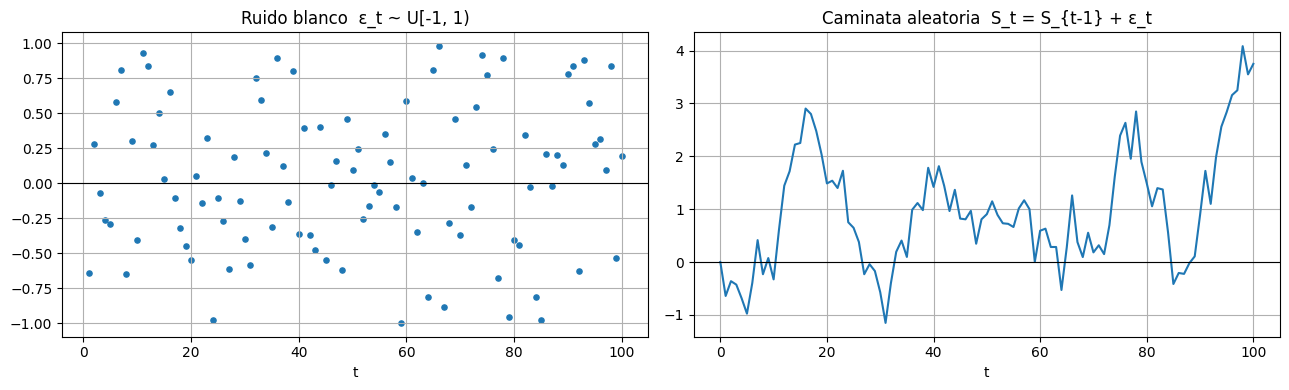

Media de ε_t = 0.037 (teórica 0) | Varianza de ε_t = 0.272 (teórica 1/3 = 0.333)


In [2]:
SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)

T = 100
t = np.arange(0, T + 1)                           # tiempo: 0, 1, ..., 100
U = np.r_[np.nan, rng.random(T)]                  # U_t ~ Uniforme[0,1)  (=ALEATORIO())
eps = (U - 0.5) / 0.5                             # ruido blanco en [-1, 1)
S = np.r_[0.0, np.cumsum(eps[1:])]                # caminata aleatoria, S_0 = 0

excel = pd.DataFrame({"Tiempo t": t, "Aleatorio U_t": U,
                      "Ruido blanco ε_t": eps, "Caminata aleatoria S_t": S})
display(excel.head(8).round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(t[1:], eps[1:], s=14)
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_title("Ruido blanco  ε_t ~ U[-1, 1)"); ax[0].set_xlabel("t")
ax[1].plot(t, S, lw=1.5)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("Caminata aleatoria  S_t = S_{t-1} + ε_t"); ax[1].set_xlabel("t")
plt.tight_layout(); plt.show()

print(f"Media de ε_t = {np.nanmean(eps):.3f} (teórica 0) | Varianza de ε_t = {np.nanvar(eps, ddof=1):.3f} (teórica 1/3 = 0.333)")

**Interpretación.**
- El **ruido blanco** oscila alrededor de cero sin ningún patrón: su media y su dispersión son las mismas al inicio y al final de la muestra (estacionario).
- La **caminata aleatoria**, construida solo con ese ruido, muestra rachas que parecen "tendencias". No lo son: son la acumulación de choques aleatorios. Un analista que viera solo esta gráfica podría estar tentado a pronosticar la "tendencia", pero el mejor pronóstico es simplemente el último valor.
- La media (0.037) y la varianza (0.272) muestrales del ruido difieren de sus valores teóricos (0 y 0.333) porque son solo 100 observaciones de **una** realización. Con muchas realizaciones (sección 3.4) los valores simulados coinciden con los teóricos.

<a id="sec-3-3"></a>
### 3.3 Muchas realizaciones (el equivalente a presionar F9)

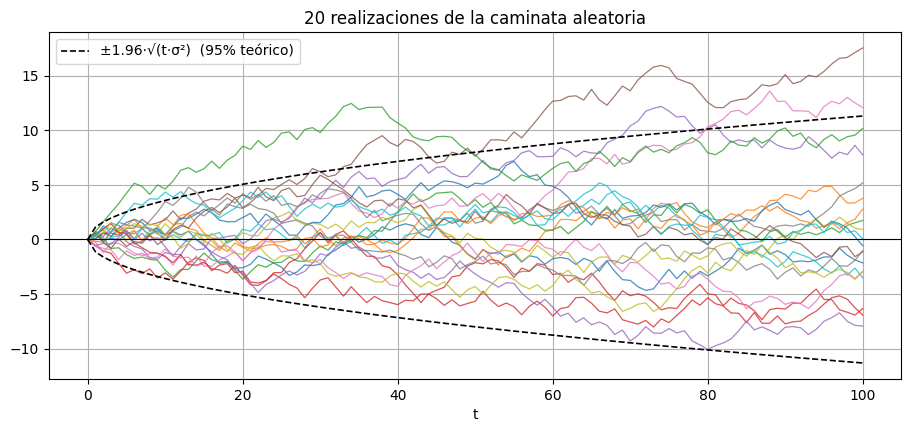

In [3]:
N_GRAF = 20
eps_m = (rng.random((N_GRAF, T)) - 0.5) / 0.5
S_m = np.hstack([np.zeros((N_GRAF, 1)), np.cumsum(eps_m, axis=1)])

sigma2 = 1 / 3
banda = 1.96 * np.sqrt(t * sigma2)                # ±1.96·√(t·σ²)

plt.figure(figsize=(11, 4.5))
plt.plot(t, S_m.T, lw=0.9, alpha=0.8)
plt.plot(t, banda, "k--", lw=1.2, label="±1.96·√(t·σ²)  (95% teórico)")
plt.plot(t, -banda, "k--", lw=1.2)
plt.axhline(0, color="k", lw=0.8)
plt.title(f"{N_GRAF} realizaciones de la caminata aleatoria"); plt.xlabel("t"); plt.legend()
plt.show()

**Interpretación.** Con el mismo mecanismo se obtienen trayectorias muy distintas: unas terminan arriba, otras abajo. Esto ilustra que una serie observada es **una sola realización** del proceso. La dispersión entre trayectorias **se abre con el tiempo** siguiendo la banda $\pm 1.96\sqrt{t\,\sigma^2}$: es la propiedad $\operatorname{Var}(S_t) = t\sigma^2$ (la persona al final de la fila que "más se cae", en la analogía de la guía).

<a id="sec-3-4"></a>
### 3.4 Verificación numérica de las propiedades (simulación de Monte Carlo)

Se simulan 10,000 caminatas y, para cada $t$, se calcula la media y la varianza **entre realizaciones**, para compararlas con los valores teóricos.

,t,E[S_t] simulada,E[S_t] teórica,Var(S_t) simulada,Var(S_t) teórica = t/3
0,10,-0.001,0.0,3.364,3.333
1,25,-0.025,0.0,8.473,8.333
2,50,-0.057,0.0,16.622,16.667
3,100,-0.065,0.0,33.158,33.333


Cov(S_50, S_100): simulada = 16.475 | teórica = min(50,100)·σ² = 16.667
Regresión S_100 = a + b·S_99: a = 0.001 (teórico 0), b = 0.999 (teórico 1)


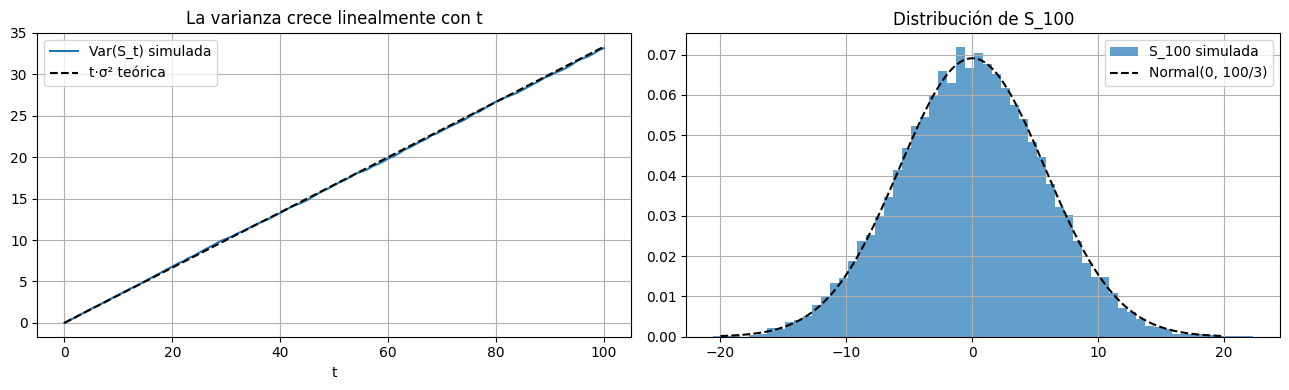

In [4]:
N_MC = 10_000
eps_mc = (rng.random((N_MC, T)) - 0.5) / 0.5
S_mc = np.hstack([np.zeros((N_MC, 1)), np.cumsum(eps_mc, axis=1)])

media_sim = S_mc.mean(axis=0)
var_sim = S_mc.var(axis=0, ddof=1)

cortes = [10, 25, 50, 100]
tabla = pd.DataFrame({
    "t": cortes,
    "E[S_t] simulada": media_sim[cortes],
    "E[S_t] teórica": 0.0,
    "Var(S_t) simulada": var_sim[cortes],
    "Var(S_t) teórica = t/3": np.array(cortes) * sigma2,
})
cov_sim = np.cov(S_mc[:, 50], S_mc[:, 100])[0, 1]
display(tabla.round(3))
print(f"Cov(S_50, S_100): simulada = {cov_sim:.3f} | teórica = min(50,100)·σ² = {50*sigma2:.3f}")

# Valor esperado condicional: E[S_t | S_{t-1}] = S_{t-1}  ->  regresión de S_t sobre S_{t-1}
x, y = S_mc[:, 99], S_mc[:, 100]
pend, inter, *_ = stats.linregress(x, y)
print(f"Regresión S_100 = a + b·S_99: a = {inter:.3f} (teórico 0), b = {pend:.3f} (teórico 1)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(t, var_sim, label="Var(S_t) simulada")
ax[0].plot(t, t * sigma2, "k--", label="t·σ² teórica")
ax[0].set_title("La varianza crece linealmente con t"); ax[0].set_xlabel("t"); ax[0].legend()
ax[1].hist(S_mc[:, 100], bins=60, density=True, alpha=0.7, label="S_100 simulada")
xs = np.linspace(-20, 20, 300)
ax[1].plot(xs, stats.norm.pdf(xs, 0, np.sqrt(100 * sigma2)), "k--", label="Normal(0, 100/3)")
ax[1].set_title("Distribución de S_100"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretación.**
- **$E[S_t] = 0$:** la media entre realizaciones es prácticamente cero en todos los cortes, aunque cada trayectoria individual casi nunca termina en cero (como advierte la guía).
- **$\operatorname{Var}(S_t) = t\sigma^2$:** la varianza simulada sigue la recta teórica $t/3$; a $t = 100$ es cercana a 33.3.
- **$\operatorname{Cov}(S_t,S_s) = \min(t,s)\sigma^2$:** la covarianza entre $S_{50}$ y $S_{100}$ es cercana a $50/3 = 16.7$, porque comparten los primeros 50 choques.
- **$E[S_t \mid S_{t-1}] = S_{t-1}$:** al regresar $S_{100}$ sobre $S_{99}$, la pendiente es 1 y el intercepto 0: el mejor pronóstico es el último valor.
- Aunque el ruido es **uniforme**, $S_{100}$ se distribuye aproximadamente **normal**: es la suma de 100 choques independientes (teorema central del límite).

<a id="sec-4"></a>
## 4. Parte 2: Ruido blanco y caminata aleatoria en las acciones seleccionadas

<small>[↑ Volver al contenido](#contenido)</small>

<a id="sec-4-1"></a>
### 4.1 Datos

Se usan las **10 acciones** del portafolio de HowTheMarketWorks y el ETF **USO** (petróleo), con precios de cierre ajustados diarios de Yahoo Finance del 2 de enero de 2015 al 6 de noviembre de 2026. Se agrupan por sector:

| Sector | Activos |
|:--|:--|
| Tecnología | AAPL (Apple), MSFT (Microsoft), NVDA (NVIDIA), GOOGL (Alphabet) |
| Bancos | JPM (JPMorgan Chase), GS (Goldman Sachs), BAC (Bank of America) |
| Energía | XOM (Exxon Mobil), CVX (Chevron), COP (ConocoPhillips) |
| ETF de petróleo | USO (United States Oil Fund) |

La fecha final se fija para que el análisis sea reproducible.

In [5]:
import yfinance as yf

TICKERS = ["AAPL", "MSFT", "NVDA", "GOOGL", "JPM", "GS", "BAC", "XOM", "CVX", "COP", "USO"]
INICIO, FIN = "2015-01-01", "2026-11-07"           # FIN no se incluye: último dato 6-nov-2026

precios = yf.download(TICKERS, start=INICIO, end=FIN, auto_adjust=True, progress=False)["Close"][TICKERS]
if precios.empty or precios.shape[1] < len(TICKERS):
    raise RuntimeError("No se pudieron descargar todos los precios de Yahoo Finance. Vuelve a correr la celda.")

faltantes = precios.isna().sum()
precios = precios.dropna()
print(f"Periodo: {precios.index[0].date()} a {precios.index[-1].date()} | {len(precios):,} días hábiles")
print("Datos faltantes eliminados por activo:", faltantes[faltantes > 0].to_dict() or "ninguno")
precios.to_csv("precios_diarios_2015_2026.csv")      # respaldo de los datos usados

p = np.log(precios)                                   # log-precio  p_t
r = 100 * p.diff().dropna()                           # rendimiento log diario en %  r_t
estad = pd.DataFrame({"Media (%)": r.mean(), "Desv. est. (%)": r.std(),
                      "Mínimo (%)": r.min(), "Fecha del mínimo": r.idxmin().dt.date,
                      "Máximo (%)": r.max(), "Fecha del máximo": r.idxmax().dt.date})
display(estad.round(3))

Periodo: 2015-01-02 a 2026-11-06 | 2,980 días hábiles
Datos faltantes eliminados por activo: ninguno


,Media (%),Desv. est. (%),Mínimo (%),Fecha del mínimo,Máximo (%),Fecha del máximo
Ticker,,,,,,
AAPL,0.089,1.804,-13.771,2020-03-16,14.262,2025-04-09
MSFT,0.087,1.735,-15.945,2020-03-16,14.416,2026-07-30
NVDA,0.200,3.008,-20.771,2018-11-16,26.088,2016-11-11
GOOGL,0.080,1.841,-13.515,2026-10-29,15.065,2015-07-17
JPM,0.067,1.689,-16.211,2020-03-16,16.562,2020-03-13
GS,0.058,1.852,-13.588,2020-03-16,16.195,2020-03-13
BAC,0.042,1.906,-16.720,2020-03-16,16.379,2020-03-13
XOM,0.036,1.733,-13.039,2020-03-09,11.944,2020-03-24
CVX,0.038,1.832,-25.006,2020-03-18,20.490,2020-03-24


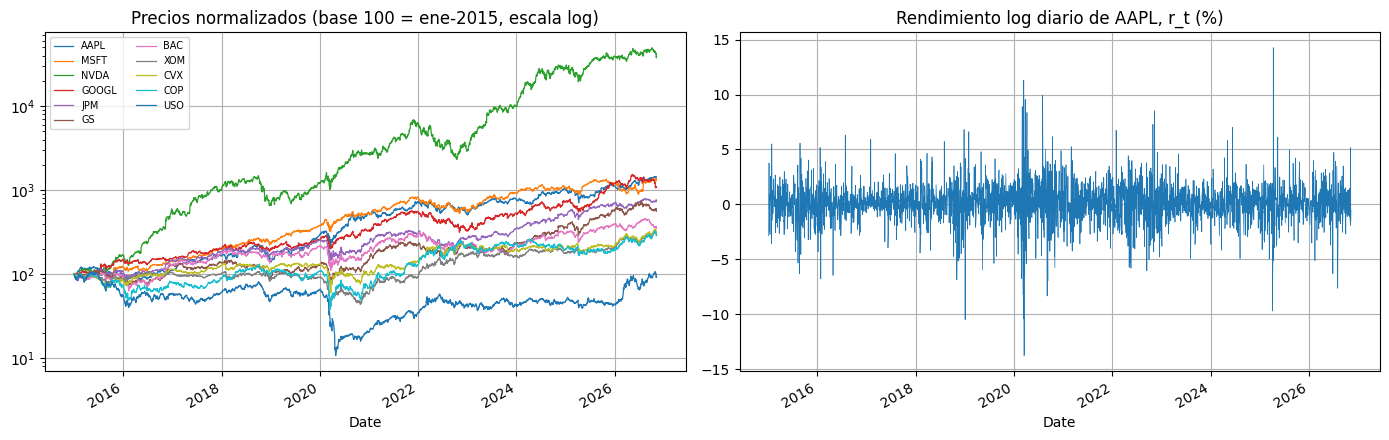

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
(100 * precios / precios.iloc[0]).plot(ax=ax[0], lw=0.9, logy=True, legend=False)
ax[0].set_title("Precios normalizados (base 100 = ene-2015, escala log)")
ax[0].legend(TICKERS, ncol=2, fontsize=7)
r["AAPL"].plot(ax=ax[1], lw=0.5)
ax[1].set_title("Rendimiento log diario de AAPL, r_t (%)")
plt.tight_layout(); plt.show()

**Interpretación.** Los precios (izquierda) se parecen a las caminatas aleatorias de la sección 3: deambulan sin regresar a un nivel fijo y su dispersión crece con el tiempo. Los rendimientos (derecha) se parecen al ruido blanco: oscilan alrededor de cero. Con una diferencia importante: hay **periodos de calma y periodos de turbulencia**, algo que el ruido blanco de la simulación no tiene.

La tabla de estadísticas lo confirma: los días extremos se **concentran en marzo de 2020**, al inicio de la pandemia. El peor día de AAPL, MSFT, JPM, GS y BAC fue el 16 de marzo de 2020; el de XOM, COP y USO, el 9 de marzo de 2020. Y el mejor día de los tres bancos fue el 13 de marzo de 2020, tres días **antes** de su peor caída. Las caídas y los rebotes grandes llegan juntos: la volatilidad se agrupa. Esto se analiza en la sección 4.4.

Por otra parte, NVDA tiene el mayor rendimiento promedio (0.200% diario) y también la mayor volatilidad (3.0%), mientras que USO es el único activo con rendimiento promedio negativo (−0.002%), algo típico de los ETFs de petróleo, que al renovar sus contratos de futuros pierden valor aunque el precio del petróleo no caiga.

<a id="sec-4-2"></a>
### 4.2 Hipótesis

Si los mercados son eficientes en su forma débil, el log-precio sigue una **caminata aleatoria con deriva**:

$$p_{i,t} = \mu_i + p_{i,t-1} + \varepsilon_{i,t} \quad\Longleftrightarrow\quad r_{i,t} = 100\,\Delta p_{i,t} = 100\,(\mu_i + \varepsilon_{i,t})$$

Es decir, **el log-precio sería no estacionario, $I(1)$, y el rendimiento sería ruido blanco** (alrededor de una media $\mu_i$, la deriva). Se verifica con cuatro pruebas:

| Sección | Pregunta | Prueba | $H_0$ |
|:--|:--|:--|:--|
| 4.3 | ¿El log-precio tiene raíz unitaria? | Dickey-Fuller aumentada (ADF) y KPSS | ADF: raíz unitaria · KPSS: estacionaria |
| 4.4 | ¿Los rendimientos están autocorrelacionados? | ACF y Ljung-Box | No hay autocorrelación |
| 4.4 | ¿Los rendimientos son independientes? | Ljung-Box sobre $r_t^2$ y ARCH-LM | No hay efectos ARCH |
| 4.5 | ¿La varianza crece proporcional al horizonte? | Razón de varianzas de Lo y MacKinlay | $VR(k) = 1$ (caminata aleatoria) |

<a id="sec-4-3"></a>
### 4.3 Raíz unitaria: ¿el log-precio es caminata aleatoria?

- **ADF:** $H_0$ = la serie tiene raíz unitaria (no estacionaria). Se usa la especificación con constante y tendencia para el log-precio y con constante para el rendimiento; el número de rezagos se elige por AIC.
- **KPSS:** prueba complementaria con la hipótesis contraria, $H_0$ = la serie es estacionaria. Si ADF no rechaza y KPSS sí rechaza, la evidencia de raíz unitaria es sólida.

In [7]:
def p_kpss(x, reg):
    with warnings.catch_warnings():                    # avisa cuando el p-valor sale de la tabla
        warnings.simplefilter("ignore")
        return kpss(x, regression=reg, nlags="auto")[1]   # p-valor acotado entre 0.01 y 0.10

filas = []
for k in TICKERS:
    adf_p = adfuller(p[k], regression="ct", autolag="AIC")[1]
    adf_r = adfuller(r[k], regression="c", autolag="AIC")[1]
    filas.append({"Activo": k,
                  "ADF log-precio (p)": adf_p, "KPSS log-precio (p)": p_kpss(p[k], "ct"),
                  "ADF rendimiento (p)": adf_r, "KPSS rendimiento (p)": p_kpss(r[k], "c")})
raiz = pd.DataFrame(filas).set_index("Activo")
raiz["Log-precio"] = np.where((raiz["ADF log-precio (p)"] >= 0.05), "No estacionario (raíz unitaria)", "Estacionario")
raiz["Rendimiento"] = np.where((raiz["ADF rendimiento (p)"] < 0.05), "Estacionario", "No estacionario")
display(raiz.round(4))

,ADF log-precio (p),KPSS log-precio (p),ADF rendimiento (p),KPSS rendimiento (p),Log-precio,Rendimiento
Activo,,,,,,
AAPL,0.2950,0.01,0.0,0.1,No estacionario (raíz unitaria),Estacionario
MSFT,0.5992,0.01,0.0,0.1,No estacionario (raíz unitaria),Estacionario
NVDA,0.5526,0.01,0.0,0.1,No estacionario (raíz unitaria),Estacionario
GOOGL,0.2059,0.01,0.0,0.1,No estacionario (raíz unitaria),Estacionario
JPM,0.3169,0.01,0.0,0.1,No estacionario (raíz unitaria),Estacionario
GS,0.4947,0.01,0.0,0.1,No estacionario (raíz unitaria),Estacionario
BAC,0.1421,0.01,0.0,0.1,No estacionario (raíz unitaria),Estacionario
XOM,0.7865,0.01,0.0,0.1,No estacionario (raíz unitaria),Estacionario
CVX,0.1368,0.01,0.0,0.1,No estacionario (raíz unitaria),Estacionario


**Nota sobre KPSS.** La tabla de valores críticos de KPSS solo cubre p-valores entre 0.01 y 0.10: un valor de 0.01 significa "0.01 o menos" y uno de 0.10, "0.10 o más".

**Interpretación.**

- **Log-precio: no estacionario en los 11 activos.** La ADF **no rechaza** la raíz unitaria en ningún caso (p-valores entre 0.137 de CVX y 0.787 de XOM) y la KPSS **rechaza** la estacionariedad en todos (p ≤ 0.01). Las dos pruebas, con hipótesis opuestas, llegan a la misma conclusión. Como la ADF incluye tendencia, la no estacionariedad no se debe solo a que los precios crezcan con el tiempo: hay una raíz unitaria.
- **Rendimiento: estacionario en los 11 activos.** La ADF rechaza la raíz unitaria (p ≈ 0) y la KPSS no rechaza la estacionariedad (p ≥ 0.10).
- **Conclusión:** el log-precio es **integrado de orden 1, $I(1)$**, y su primera diferencia, el rendimiento, es **$I(0)$**. Es exactamente la relación entre la caminata aleatoria $S_t$ y el ruido blanco $\varepsilon_t$ de la Parte 1. Para modelos ARIMA esto implica usar $d = 1$ sobre el log-precio, o modelar directamente los rendimientos con $d = 0$.

<a id="sec-4-4"></a>
### 4.4 Ruido blanco: ¿los rendimientos están autocorrelacionados? ¿son independientes?

Si $r_t$ es ruido blanco, ninguna autocorrelación debería ser significativa. Se revisa la **función de autocorrelación (ACF)** y la prueba de **Ljung-Box** con 10 y 20 rezagos.

Pero ruido blanco en sentido estricto también exige **independencia**. Una forma de detectar dependencia no lineal es revisar si los **rendimientos al cuadrado** ($r_t^2$, una aproximación de la volatilidad) están autocorrelacionados, con Ljung-Box sobre $r_t^2$ y la prueba ARCH-LM de Engle.

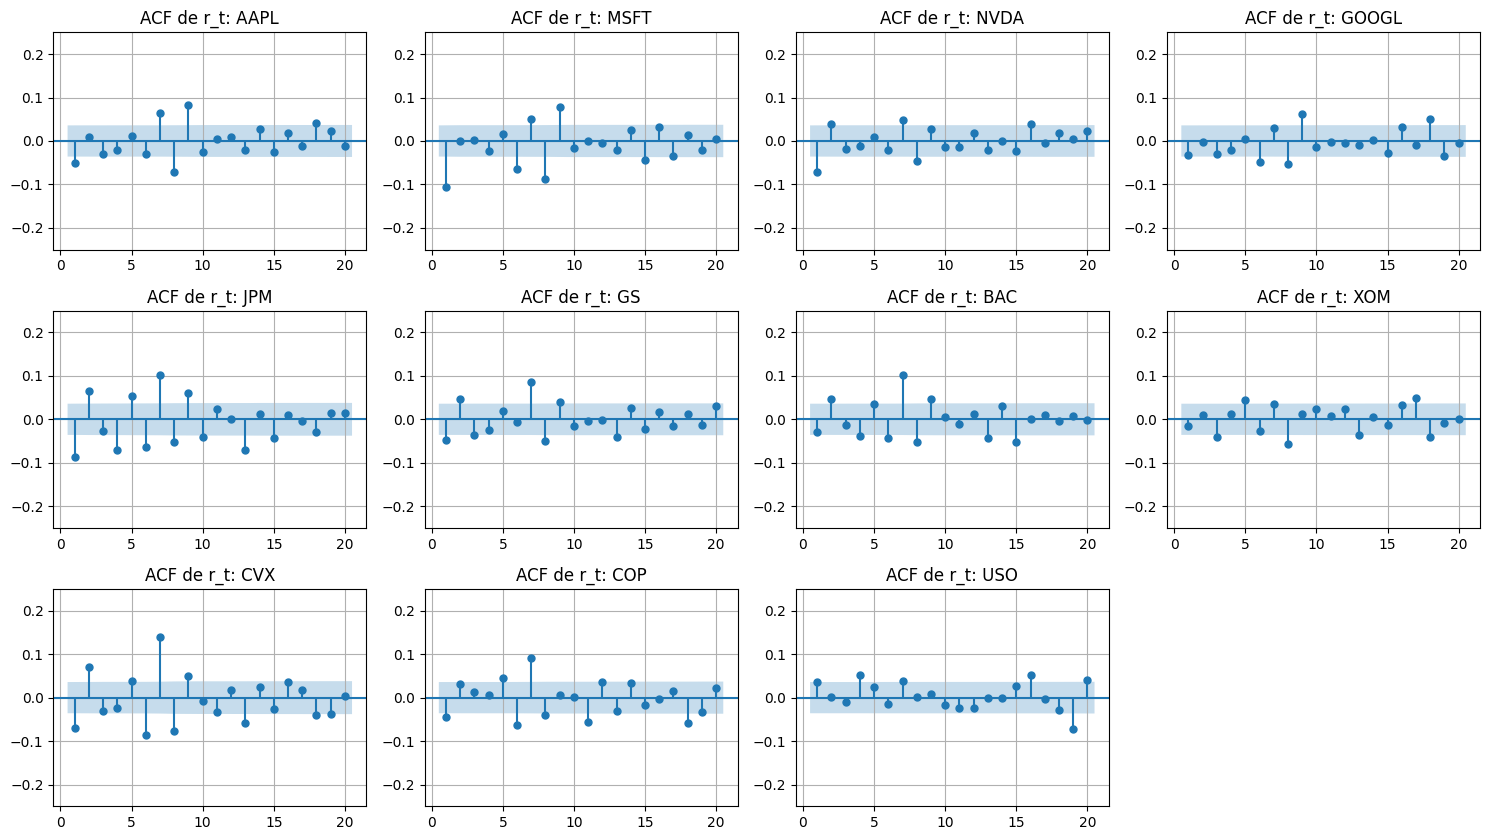

,ρ1 (rezago 1),"Ljung-Box r_t, 10 rez. (p)","Ljung-Box r_t, 20 rez. (p)","Ljung-Box r_t², 10 rez. (p)","ARCH-LM, 10 rez. (p)",¿r_t sin autocorrelación?,¿Efectos ARCH?
Activo,,,,,,,
AAPL,-0.0504,0.0000,0.0000,0.0,0.0,No,Sí
MSFT,-0.1063,0.0000,0.0000,0.0,0.0,No,Sí
NVDA,-0.0713,0.0000,0.0002,0.0,0.0,No,Sí
GOOGL,-0.0320,0.0001,0.0001,0.0,0.0,No,Sí
JPM,-0.0873,0.0000,0.0000,0.0,0.0,No,Sí
GS,-0.0470,0.0000,0.0000,0.0,0.0,No,Sí
BAC,-0.0303,0.0000,0.0000,0.0,0.0,No,Sí
XOM,-0.0143,0.0008,0.0001,0.0,0.0,No,Sí
CVX,-0.0706,0.0000,0.0000,0.0,0.0,No,Sí


In [8]:
fig, axes = plt.subplots(3, 4, figsize=(15, 8.5))
for ax, k in zip(axes.flat, TICKERS):
    plot_acf(r[k], lags=20, ax=ax, zero=False, title=f"ACF de r_t: {k}")
    ax.set_ylim(-0.25, 0.25)
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()

filas = []
for k in TICKERS:
    lb = acorr_ljungbox(r[k], lags=[10, 20], return_df=True)["lb_pvalue"]
    lb2 = acorr_ljungbox(r[k] ** 2, lags=[10], return_df=True)["lb_pvalue"].iloc[0]
    arch_p = het_arch(r[k] - r[k].mean(), nlags=10)[1]
    filas.append({"Activo": k, "ρ1 (rezago 1)": r[k].autocorr(1),
                  "Ljung-Box r_t, 10 rez. (p)": lb.iloc[0], "Ljung-Box r_t, 20 rez. (p)": lb.iloc[1],
                  "Ljung-Box r_t², 10 rez. (p)": lb2, "ARCH-LM, 10 rez. (p)": arch_p})
rb = pd.DataFrame(filas).set_index("Activo")
rb["¿r_t sin autocorrelación?"] = np.where(rb["Ljung-Box r_t, 10 rez. (p)"] >= 0.05, "Sí", "No")
rb["¿Efectos ARCH?"] = np.where(rb["ARCH-LM, 10 rez. (p)"] < 0.05, "Sí", "No")
display(rb.round(4))

**Una advertencia sobre Ljung-Box.** La prueba de Ljung-Box supone que la varianza de los rendimientos es constante. Cuando hay efectos ARCH (volatilidad agrupada), sus valores p salen demasiado pequeños y tiende a "encontrar" autocorrelación que no existe (Brooks, 2008). Por eso se complementa con una prueba **robusta a heteroscedasticidad**: se estima por MCO

$$r_{i,t} = c + \phi_1 r_{i,t-1} + \dots + \phi_5 r_{i,t-5} + u_{i,t}$$

con errores estándar de White (HC0), y se prueba si $\phi_1 = 0$ y si $\phi_1 = \dots = \phi_5 = 0$ en conjunto.

In [9]:
import statsmodels.api as sm

filas = []
for k in TICKERS:
    rez = pd.concat({f"L{j}": r[k].shift(j) for j in range(1, 6)}, axis=1)
    datos = pd.concat([r[k].rename("y"), rez], axis=1).dropna()
    m = sm.OLS(datos["y"], sm.add_constant(datos[[f"L{j}" for j in range(1, 6)]])).fit(cov_type="HC0")
    conj = m.wald_test("L1 = 0, L2 = 0, L3 = 0, L4 = 0, L5 = 0", scalar=True)
    filas.append({"Activo": k, "φ1": m.params["L1"], "p de φ1 (robusto)": m.pvalues["L1"],
                  "p conjunto φ1..φ5 (robusto)": float(conj.pvalue)})
rob = pd.DataFrame(filas).set_index("Activo")
rob["¿Autocorrelación significativa (robusta, 5%)?"] = np.where(rob["p conjunto φ1..φ5 (robusto)"] < 0.05, "Sí", "No")
display(rob.round(4))

,φ1,p de φ1 (robusto),p conjunto φ1..φ5 (robusto),"¿Autocorrelación significativa (robusta, 5%)?"
Activo,,,,
AAPL,-0.0508,0.1099,0.5746,No
MSFT,-0.1074,0.0026,0.0677,No
NVDA,-0.0689,0.0082,0.0850,No
GOOGL,-0.0335,0.1868,0.4988,No
JPM,-0.0795,0.0716,0.1025,No
GS,-0.0441,0.2735,0.4396,No
BAC,-0.0278,0.5012,0.5516,No
XOM,-0.0141,0.6325,0.3940,No
CVX,-0.0635,0.1001,0.5088,No


**Interpretación.**

- **Autocorrelación de los rendimientos (ACF y Ljung-Box).** Casi todas las barras de la ACF quedan dentro o muy cerca de las bandas de confianza. La autocorrelación de primer orden es pequeña y negativa en 10 de los 11 activos (de −0.014 en XOM a −0.106 en MSFT) y positiva en USO (+0.036). Aun así, Ljung-Box rechaza "sin autocorrelación" en los 11 activos.
- **Volatilidad agrupada.** Ljung-Box sobre $r_t^2$ y la prueba ARCH-LM rechazan en los 11 activos (p ≈ 0): la varianza de los rendimientos **no es constante**. Un día muy volátil tiende a seguir a otro día muy volátil, como en marzo de 2020 (sección 4.1).
- **Prueba robusta.** Al corregir por heteroscedasticidad, **ningún activo** muestra autocorrelación conjunta significativa en los primeros 5 rezagos (p-valores entre 0.068 de MSFT y 0.675 de USO). Individualmente, solo $\phi_1$ es significativo en **MSFT** (−0.107; p = 0.003) y **NVDA** (−0.069; p = 0.008): una ligera reversión al día siguiente. Su efecto es económicamente pequeño: una autocorrelación de −0.1 explica alrededor de 1% de la variación del rendimiento del día siguiente, insuficiente para una estrategia rentable una vez descontados los costos de transacción.
- **Conclusión.** El rechazo de Ljung-Box se debe sobre todo a la heteroscedasticidad, no a una autocorrelación real. Los rendimientos son **prácticamente no correlacionados** (ruido blanco en sentido débil, alrededor de su media), pero **no independientes**: su varianza sí depende del pasado. Por eso no son ruido blanco en sentido estricto (*i.i.d.*). En términos de pronóstico: la media de los rendimientos es casi impredecible, pero su **volatilidad sí es predecible**, que es lo que modelan los modelos GARCH.

<a id="sec-4-5"></a>
### 4.5 Razón de varianzas: ¿la varianza crece proporcional al horizonte?

La tercera propiedad de la caminata aleatoria, $\operatorname{Var}(S_t) = t\sigma^2$, implica que la varianza del rendimiento a $k$ días debe ser $k$ veces la varianza del rendimiento a 1 día. La **razón de varianzas** de Lo y MacKinlay (1988) lo prueba directamente:

$$VR(k) = \frac{\operatorname{Var}(p_t - p_{t-k})}{k \cdot \operatorname{Var}(p_t - p_{t-1})}$$

- $VR(k) = 1$: consistente con caminata aleatoria.
- $VR(k) > 1$: autocorrelación positiva (*momentum*).
- $VR(k) < 1$: autocorrelación negativa (reversión a la media).

Se usa el estadístico $z^*$, robusto a heteroscedasticidad, porque la sección 4.4 muestra que la varianza de los rendimientos no es constante.

In [10]:
def razon_varianzas(logp, k):
    # Lo y MacKinlay (1988), con estadístico z* robusto a heteroscedasticidad
    x = np.asarray(logp, dtype=float)
    d = np.diff(x); n = len(d); mu = d.mean()
    var1 = np.sum((d - mu) ** 2) / (n - 1)
    dk = x[k:] - x[:-k]
    m = k * (n - k + 1) * (1 - k / n)
    vark = np.sum((dk - k * mu) ** 2) / m
    vr = vark / var1
    e2 = (d - mu) ** 2
    theta = 0.0
    for j in range(1, k):
        delta = n * np.sum(e2[j:] * e2[:-j]) / np.sum(e2) ** 2
        theta += (2 * (k - j) / k) ** 2 * delta
    z = (vr - 1) / np.sqrt(theta / n)                  # Var(VR) ≈ θ/n
    return vr, z, 2 * (1 - stats.norm.cdf(abs(z)))

filas = []
for k in TICKERS:
    fila = {"Activo": k}
    for h in (5, 20):
        vr, z, pv = razon_varianzas(p[k], h)
        fila[f"VR({h})"] = vr; fila[f"z*({h})"] = z; fila[f"p({h})"] = pv
    filas.append(fila)
vrt = pd.DataFrame(filas).set_index("Activo")
display(vrt.round(3))

,VR(5),z*(5),p(5),VR(20),z*(20),p(20)
Activo,,,,,,
AAPL,0.901,-1.442,0.149,0.904,-0.673,0.501
MSFT,0.822,-2.255,0.024,0.706,-1.945,0.052
NVDA,0.911,-1.590,0.112,0.888,-0.970,0.332
GOOGL,0.913,-1.597,0.110,0.800,-1.724,0.085
JPM,0.890,-1.092,0.275,0.838,-0.792,0.429
GS,0.942,-0.669,0.503,0.974,-0.149,0.881
BAC,0.983,-0.194,0.846,1.026,0.140,0.889
XOM,0.961,-0.581,0.561,1.006,0.038,0.970
CVX,0.938,-0.600,0.548,0.932,-0.281,0.779


**Interpretación.**

- Las razones de varianzas están cerca de 1: $VR(5)$ va de 0.82 (MSFT) a 1.07 (USO) y $VR(20)$ de 0.71 (MSFT) a 1.18 (USO). La mayoría son menores que 1, una ligera reversión a la media congruente con las autocorrelaciones negativas de la sección 4.4; USO es mayor que 1, congruente con su autocorrelación positiva.
- Con el estadístico robusto $z^*$, **10 de los 11 activos no rechazan** $VR = 1$ en ningún horizonte. La excepción es **MSFT a 5 días** (p = 0.024), y a 20 días queda en el límite (p = 0.052): coincide con su $\phi_1$ negativo y significativo.
- **Advertencia sobre pruebas múltiples:** con 22 pruebas al 5%, se espera alrededor de un rechazo solo por azar, así que la evidencia contra la caminata aleatoria en MSFT es débil.
- **Conclusión:** la varianza crece aproximadamente en proporción al horizonte, como en la tercera propiedad de la caminata aleatoria ($\operatorname{Var}(S_t) = t\sigma^2$) verificada en la sección 3.4.

<a id="sec-4-6"></a>
### 4.6 ¿Se distingue una acción de una caminata aleatoria simulada?

Se simula una caminata aleatoria con deriva usando la media y la desviación estándar del rendimiento diario de AAPL y se compara con su log-precio real.

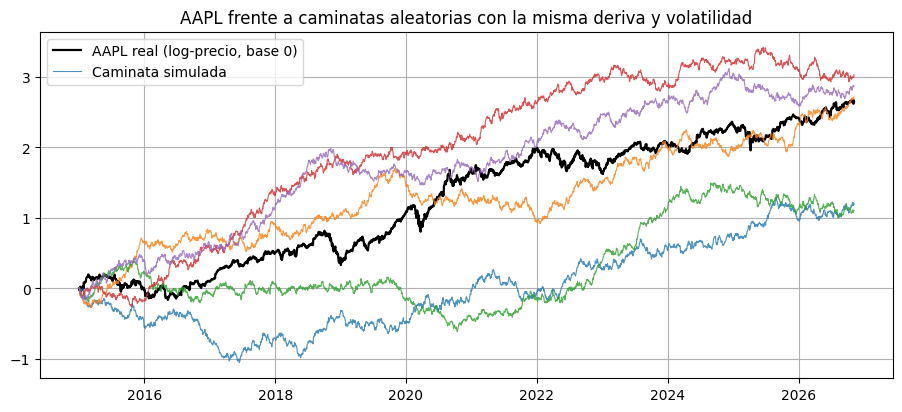

In [11]:
k = "AAPL"
mu_k, sd_k = r[k].mean() / 100, r[k].std() / 100
rng_sim = np.random.default_rng(7)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(p.index, p[k] - p[k].iloc[0], lw=1.6, color="k", label=f"{k} real (log-precio, base 0)")
for s in range(5):
    sim = np.r_[0, np.cumsum(mu_k + sd_k * rng_sim.standard_normal(len(p) - 1))]
    ax.plot(p.index, sim, lw=0.8, alpha=0.8, label="Caminata simulada" if s == 0 else None)
ax.set_title(f"{k} frente a caminatas aleatorias con la misma deriva y volatilidad"); ax.legend()
plt.show()

**Interpretación.** Visualmente, la serie real no se distingue de las caminatas simuladas con la misma deriva y volatilidad. Por eso hacen falta las pruebas formales de las secciones 4.3 a 4.5: a simple vista, cualquier caminata aleatoria parece tener "tendencias" que invitan a pronosticar.

<a id="sec-4-7"></a>
### 4.7 Resumen por activo

In [12]:
resumen = pd.DataFrame({
    "Log-precio (ADF/KPSS)": raiz["Log-precio"],
    "Rendimiento (ADF)": raiz["Rendimiento"],
    "r_t sin autocorrelación (Ljung-Box 10)": rb["¿r_t sin autocorrelación?"],
    "r_t sin autocorrelación (prueba robusta)": np.where(rob["p conjunto φ1..φ5 (robusto)"] >= 0.05, "Sí", "No"),
    "Efectos ARCH (volatilidad agrupada)": rb["¿Efectos ARCH?"],
    "VR(20) = 1 (p ≥ 0.05)": np.where(vrt["p(20)"] >= 0.05, "Sí", "No"),
})
display(resumen)

,Log-precio (ADF/KPSS),Rendimiento (ADF),r_t sin autocorrelación (Ljung-Box 10),r_t sin autocorrelación (prueba robusta),Efectos ARCH (volatilidad agrupada),VR(20) = 1 (p ≥ 0.05)
Activo,,,,,,
AAPL,No estacionario (raíz unitaria),Estacionario,No,Sí,Sí,Sí
MSFT,No estacionario (raíz unitaria),Estacionario,No,Sí,Sí,Sí
NVDA,No estacionario (raíz unitaria),Estacionario,No,Sí,Sí,Sí
GOOGL,No estacionario (raíz unitaria),Estacionario,No,Sí,Sí,Sí
JPM,No estacionario (raíz unitaria),Estacionario,No,Sí,Sí,Sí
GS,No estacionario (raíz unitaria),Estacionario,No,Sí,Sí,Sí
BAC,No estacionario (raíz unitaria),Estacionario,No,Sí,Sí,Sí
XOM,No estacionario (raíz unitaria),Estacionario,No,Sí,Sí,Sí
CVX,No estacionario (raíz unitaria),Estacionario,No,Sí,Sí,Sí


**Interpretación general.** Los 11 activos se comportan igual: log-precio no estacionario, rendimiento estacionario, sin autocorrelación significativa una vez que se corrige por heteroscedasticidad, con efectos ARCH y con una razón de varianzas a 20 días congruente con la caminata aleatoria. En la clasificación de Campbell, Lo y MacKinlay (1997), los precios son consistentes con una **caminata aleatoria con incrementos no correlacionados pero heteroscedásticos**, y no con la versión más estricta, de incrementos *i.i.d.*, que es la que se simuló en la Parte 1.

<a id="sec-5"></a>
## 5. Conclusiones

<small>[↑ Volver al contenido](#contenido)</small>

1. **La simulación confirma la teoría.** El ruido blanco construido en Excel y en Python es estacionario, y su acumulación, la caminata aleatoria, no lo es. Con 10,000 realizaciones se verificaron las cuatro propiedades de la guía: $E[S_t] \approx 0$, $E[S_t \mid S_{t-1}] = S_{t-1}$ (pendiente de 0.999), $\operatorname{Var}(S_{100}) = 33.16$ frente a 33.33 teórico, y $\operatorname{Cov}(S_{50}, S_{100}) = 16.48$ frente a 16.67 teórico.
2. **Una sola trayectoria engaña.** Tanto en el Excel como con las acciones, una caminata aleatoria muestra rachas que parecen tendencias. No se puede decidir a simple vista si una serie es caminata aleatoria (sección 4.6); hacen falta pruebas formales.
3. **Respuesta a la pregunta de la guía: sí se puede.** Con las pruebas ADF y KPSS, de autocorrelación y de razón de varianzas, los precios de las 10 acciones y de USO resultan **no estacionarios, $I(1)$**, y sus rendimientos **estacionarios**, con autocorrelación prácticamente nula. Los precios se comportan como una caminata aleatoria con deriva, en línea con la **eficiencia débil del mercado**: los precios pasados casi no ayudan a pronosticar el rendimiento de mañana. La única excepción relevante es una ligera reversión de un día en MSFT y NVDA, económicamente pequeña.
4. **Pero no son ruido blanco en sentido estricto.** Los rendimientos no son independientes: su volatilidad se agrupa, como mostraron los días extremos de marzo de 2020 y las pruebas ARCH-LM en los 11 activos.
5. **Implicaciones para el proyecto final.**
   - En los modelos ARIMA se usará $d = 1$ sobre el log-precio (o $d = 0$ sobre los rendimientos), y se espera que el pronóstico de la media no supere por mucho al pronóstico ingenuo, el último precio.
   - El valor predictivo está en la **volatilidad**: los efectos ARCH justifican modelos GARCH para pronosticar el riesgo del portafolio.
   - En las regresiones con rendimientos diarios conviene usar **errores estándar robustos** a heteroscedasticidad.
6. **Limitaciones.** El análisis usa datos diarios de 2015 a 2026, que incluyen el choque de 2020; con 11 activos y varias pruebas al 5% es posible algún rechazo por azar; y los p-valores de la KPSS están acotados entre 0.01 y 0.10.

<a id="sec-6"></a>
## 6. Referencias

<small>[↑ Volver al contenido](#contenido)</small>

Gujarati, D. N., y Porter, D. C. (2009). *Econometría* (5.ª ed.). McGraw-Hill. Capítulos 21 y 22.

Brooks, C. (2008). *Introductory econometrics for finance* (2.ª ed.). Cambridge University Press.

Campbell, J. Y., Lo, A. W., y MacKinlay, A. C. (1997). *The econometrics of financial markets*. Princeton University Press.

Lo, A. W., y MacKinlay, A. C. (1988). Stock market prices do not follow random walks: Evidence from a simple specification test. *The Review of Financial Studies, 1*(1), 41–66.

Instituto Tecnológico y de Estudios Superiores de Monterrey. (2018). *Actividad 2.1: Procesos estocásticos estacionarios. Ruido blanco y caminata aleatoria* [Material del curso].

Bianchi, F. M. (s. f.). *Time series analysis with Python: Introduction to time series analysis* [Python Time Series Handbook]. https://filippomb.github.io/python-time-series-handbook/

Yahoo Finance. (2026). *Precios históricos diarios* [Conjunto de datos], consultado mediante la librería `yfinance`.

---

**Nota sobre el uso de inteligencia artificial.** Para elaborar el código en Python y apoyar la redacción se utilizó Claude (Anthropic) como asistente. Los cálculos se ejecutaron en Google Colab con datos descargados de Yahoo Finance, y los resultados e interpretaciones fueron revisados por el alumno.